In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def hamiltonian_matrix(delta_x,potential_values):
    potential_values=np.asarray(potential_values,dtype=float)
    interior_points=len(potential_values)
    main_diag=1/(delta_x**2)+potential_values
    off_diag=np.full(interior_points-1,-1/(2*(delta_x**2)))
    hamiltonian=(np.diag(main_diag)+np.diag(off_diag,k=1)+np.diag(off_diag,k=-1))
    return hamiltonian

In [3]:
def energy_variation(xi,xf,interior_points,potential_func):
    delta_x=(xf-xi)/(interior_points+1)
    interior_grid=(xi+delta_x*np.arange(1,interior_points+1))

    potential_values=potential_func(interior_grid)

    H=hamiltonian_matrix(delta_x,potential_values)
    eigenvalues,eigenvectors=np.linalg.eigh(H)

    n_i=0
    n_f=len(eigenvalues)
    step=1
    n=np.arange(n_i,n_f,step)
    plt.plot(n[:200],eigenvalues[:200])
    plt.xlabel("quantum number(n)")
    plt.ylabel("energy value")
    plt.title("variation of energy with quantum number")
    plt.grid(alpha=0.7)
    plt.show()

In [4]:
def infinte_potential_well(interior_grid):
  n = len(interior_grid)
  potential_values = np.zeros(n)
  return potential_values

def solve_and_plot(xi,xf,interior_points,state_index):
  delta_x = (xf - xi)/(interior_points + 1)
  interior_grid = (xi + delta_x*np.arange(1,interior_points+1))

  potential_values = infinte_potential_well(interior_grid)

  if state_index < 0 or state_index >= interior_points:
    raise ValueError("state_index must lie between 0 and interior_points - 1.")

  H = hamiltonian_matrix(delta_x,potential_values)

  eigenvalues,eigenvectors = np.linalg.eigh(H)

  phi_interior   = eigenvectors[:,state_index]
  energy_value   = eigenvalues[state_index]
  phi            = np.concatenate(([0.0],phi_interior,[0.0]))
  normalization  = np.sum(np.abs(phi)**2)*delta_x
  phi_normalized = phi/np.sqrt(normalization)
  full_grid      = np.concatenate(([xi],interior_grid,[xf]))
  quantum_number = state_index + 1

  plt.plot(full_grid,phi_normalized,label=f"State {quantum_number}")
  plt.axhline(0,linewidth=0.8,linestyle="--")
  plt.xlabel("Dimensionless position, x")
  plt.ylabel(r"Eigenvector $\phi(x)$")
  plt.title(f"Eigenvalue n = {quantum_number}, "f"Energy = {energy_value:.6f}")
  plt.grid(alpha=0.3)
  plt.legend()
  plt.show()

  return full_grid,phi,energy_value

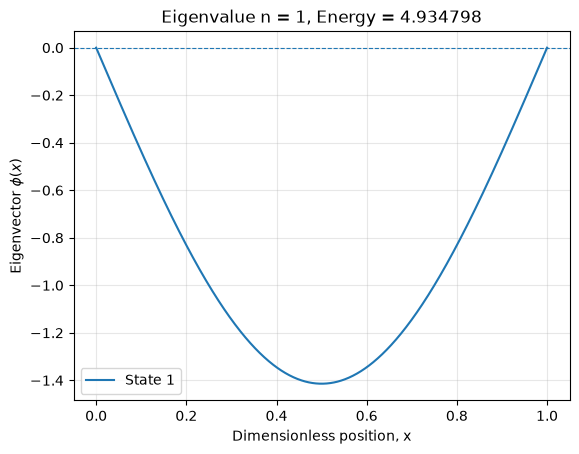

Energy = 4.9347981500691285


In [5]:

interior_points = 1000

x, phi, energy = solve_and_plot(
    xi=0,
    xf=1,
    interior_points=interior_points,
    state_index=0
)
print("Energy =", energy)

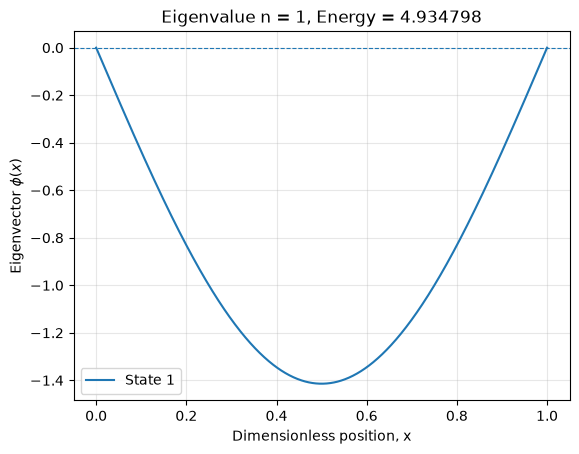

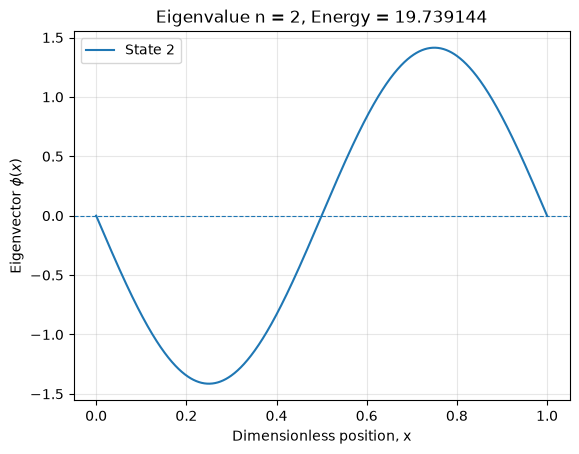

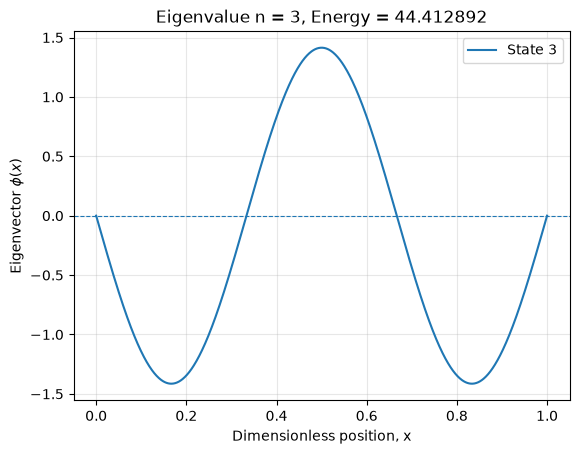

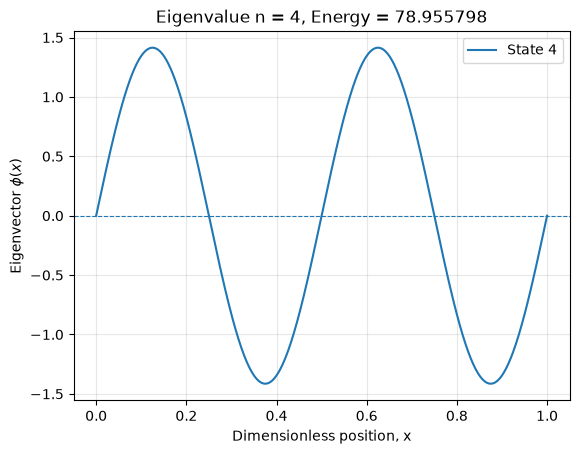

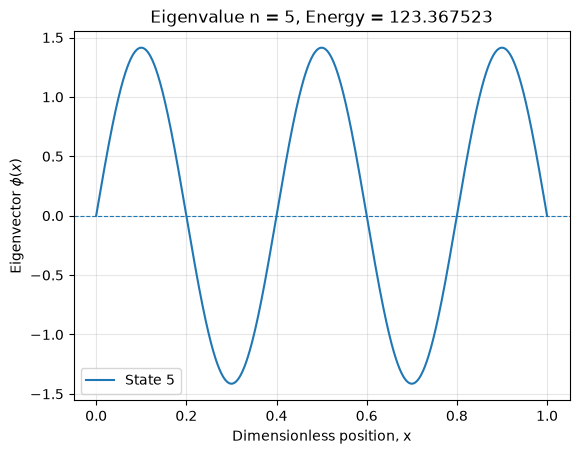

In [6]:
interior_points = 1000
states = [0, 1, 2, 3, 4]

for state_index in states:
    x, phi, energy = solve_and_plot(
        xi=0,
        xf=1,
        interior_points=interior_points,
        state_index=state_index
    )

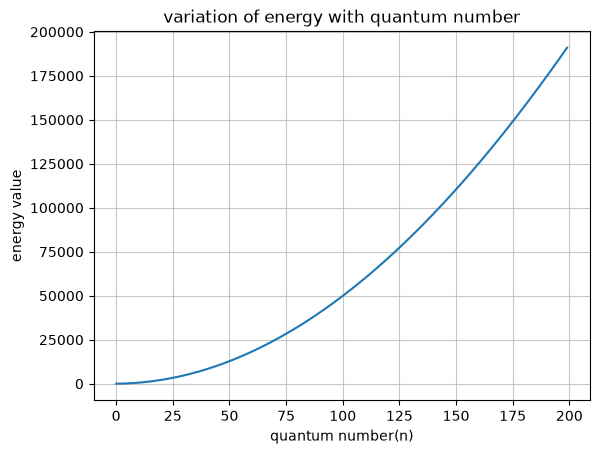

In [7]:
xi = 0
xf = 1
interior_points = 1000

energy_variation(
    xi=xi,
    xf=xf,
    interior_points=interior_points,
    potential_func=infinte_potential_well
)

In [8]:
def probability_distribution(xi,xf,interior_points,state_index,potential_values):
    delta_x = (xf-xi)/(interior_points+1)
    interior_grid = xi + delta_x*np.arange(1,interior_points+1)

    potential_values = np.asarray(potential_values,dtype=float)

    H = hamiltonian_matrix(delta_x,potential_values)

    eigenvalues,eigenvectors = np.linalg.eigh(H)

    phi_interior = eigenvectors[:,state_index]
    energy_value = eigenvalues[state_index]

    phi = np.concatenate(([0.0],phi_interior,[0.0]))

    normalization = np.sum(np.abs(phi)**2)*delta_x
    phi_normalized = phi/np.sqrt(normalization)

    full_grid = np.concatenate(([xi],interior_grid,[xf]))

    probability_curve_raw = np.abs(phi)**2
    probability_curve = np.abs(phi_normalized)**2

    area_non_normalized = delta_x*np.sum(probability_curve_raw)
    area_normalized = delta_x*np.sum(probability_curve)

    fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,4))

    ax1.plot(full_grid,probability_curve_raw)
    ax1.set_xlabel("Dimensionless position, x")
    ax1.set_ylabel(r"$|\phi(x)|^2$")
    ax1.set_title(f"Non-normalized Area = {area_non_normalized:.5f}")

    ax2.plot(full_grid,probability_curve)
    ax2.set_xlabel("Dimensionless position, x")
    ax2.set_ylabel(r"$|\phi(x)|^2$")
    ax2.set_title(f"Normalized Area = {area_normalized:.5f}")

    plt.tight_layout()
    plt.show()

    return full_grid,probability_curve,energy_value

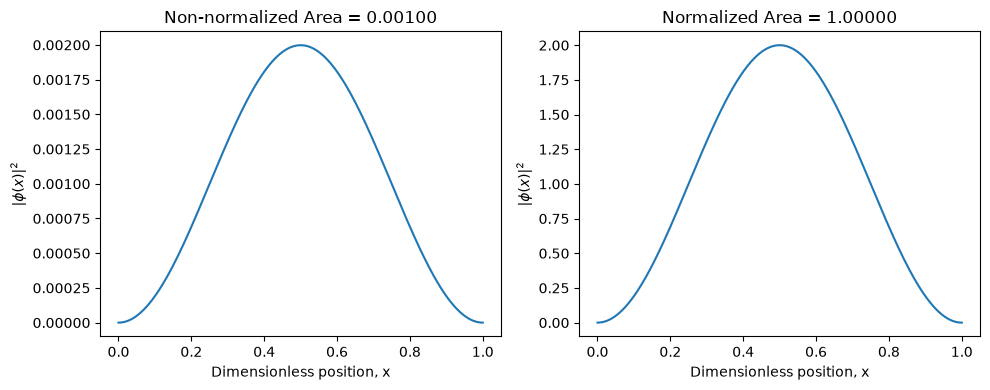

In [10]:
interior_points = 1000
potential_values = np.zeros(interior_points)

x, phi, energy = probability_distribution(
    0, 1, interior_points, 0, potential_values
)

In [11]:
def step_potential(x, x0, V0):
    potential = np.zeros(len(x))
    potential[x >= x0] = V0
    
    return potential

In [12]:
def solve_step_potential(xi, xf, interior_points, state_index, x0, V0):
    delta_x = (xf - xi) / (interior_points + 1)

    interior_grid = xi + delta_x * np.arange(1, interior_points + 1)

    potential_values = step_potential(interior_grid, x0, V0)

    H = hamiltonian_matrix(delta_x, potential_values)

    eigenvalues, eigenvectors = np.linalg.eigh(H)

    phi_interior = eigenvectors[:, state_index]
    energy_value = eigenvalues[state_index]

    phi = np.concatenate(([0], phi_interior, [0]))

    normalization = np.sum(np.abs(phi)**2) * delta_x
    phi_normalized = phi / np.sqrt(normalization)

    full_grid = np.concatenate(([xi], interior_grid, [xf]))

    return phi, full_grid, phi_normalized, energy_value

In [13]:
def plot_step_potential(full_grid, phi_normalized, energy_value, state_index, x0):
    quantum_number = state_index + 1

    plt.plot(full_grid, phi_normalized)
    plt.axhline(0, linestyle="--")
    plt.axvline(x0)

    plt.xlabel("Dimensionless position, x")
    plt.ylabel(r"Wavefunction $\phi(x)$")
    plt.title(f"State n = {quantum_number}, Energy = {energy_value:.6f}")

    plt.grid()
    plt.show()

Energy = 8.750251104676726


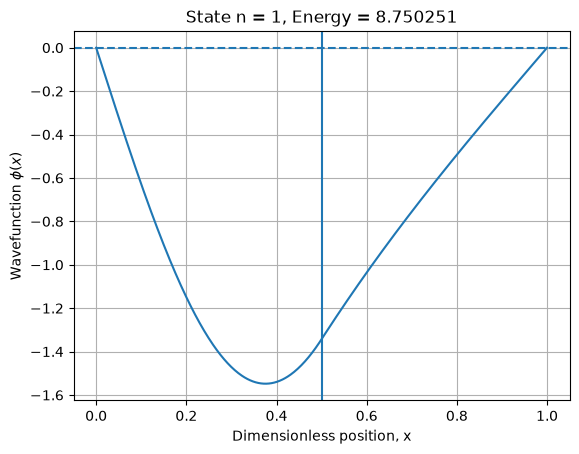

In [14]:
interior_points = 500

phi, x, phi_normalized, energy = solve_step_potential(
    0, 1, interior_points, 0, 0.5, 10
)

print("Energy =", energy)

plot_step_potential(
    x, phi_normalized, energy, 0, 0.5
)

V0 = 0
Energy = 4.934701740655757


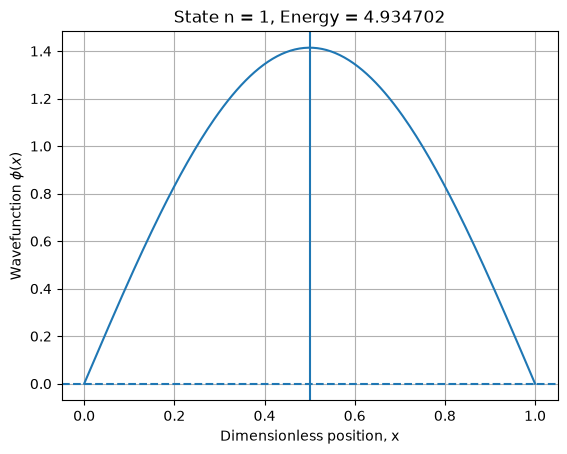

V0 = 25
Energy = 11.525874441343905


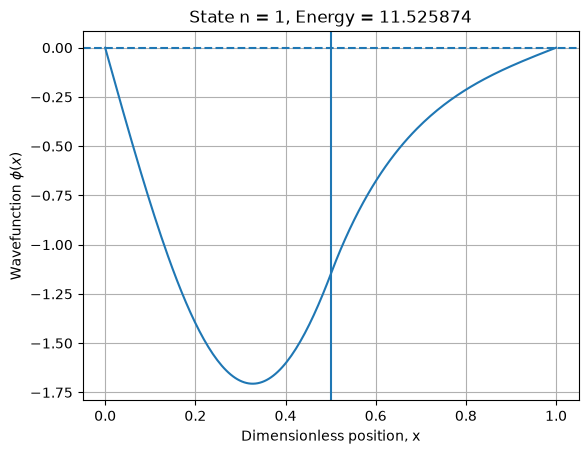

V0 = 50
Energy = 13.475411296720972


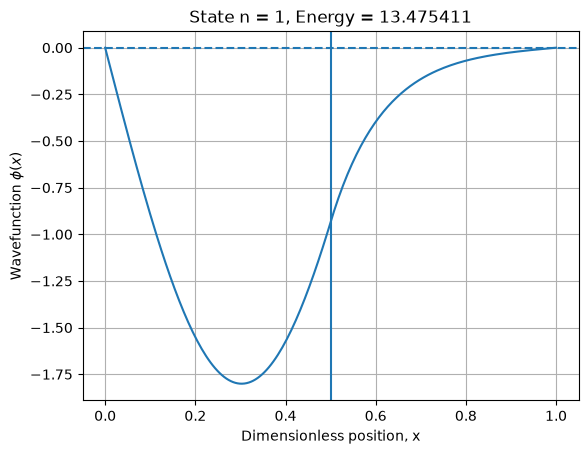

V0 = 75
Energy = 14.440814426673969


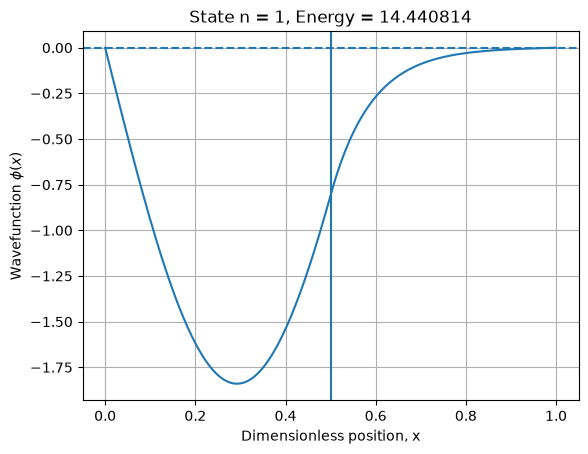

V0 = 100
Energy = 15.047293327162109


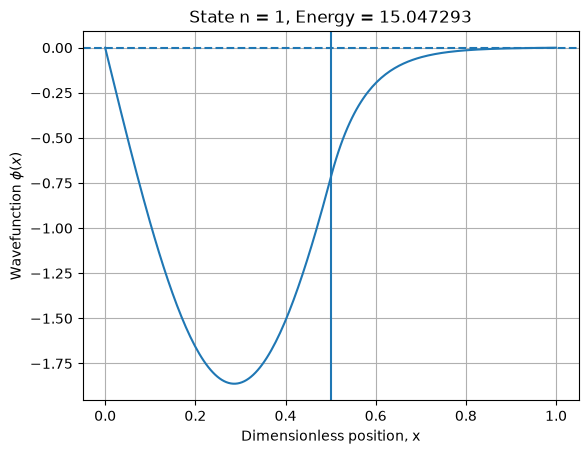

In [15]:
Vo_i = 0
Vo_f = 100
step = 25

Vo_arr = np.arange(Vo_i, Vo_f + step, step)

interior_points = 200
x0 = 0.5
state_index = 0

for V0 in Vo_arr:
    phi, full_grid, phi_normalized, energy_value = solve_step_potential(
        0, 1, interior_points, state_index, x0, V0
    )

    print("V0 =", V0)
    print("Energy =", energy_value)

    plot_step_potential(
        full_grid, phi_normalized, energy_value, state_index, x0
    )

State = 1
Energy = 15.047293327162109


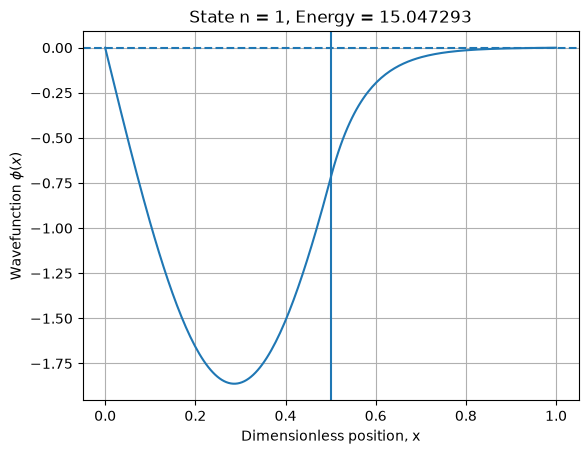

State = 2
Energy = 58.55671175282991


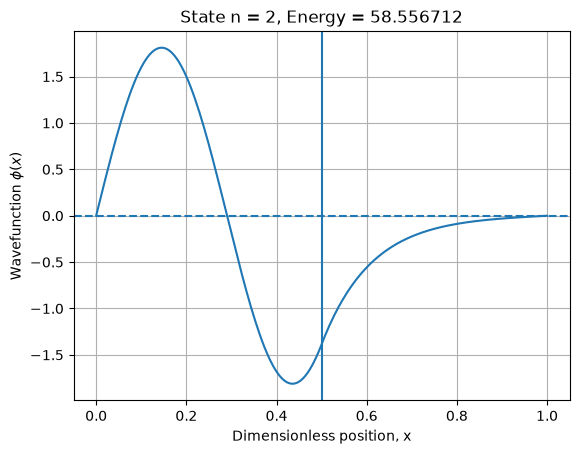

State = 3
Energy = 111.94001711516616


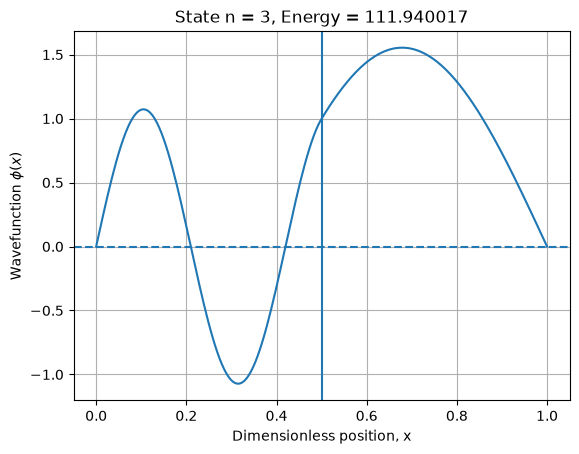

State = 4
Energy = 133.8629021425201


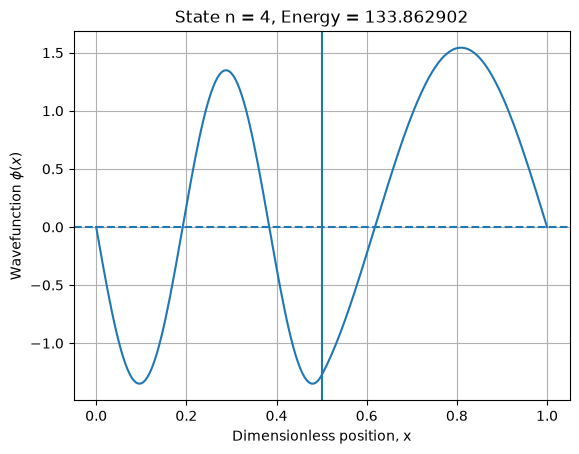

State = 5
Energy = 178.50007227797948


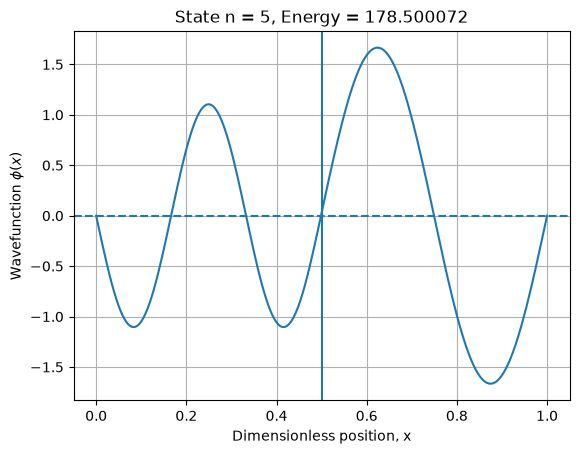

State = 6
Energy = 232.26580049806412


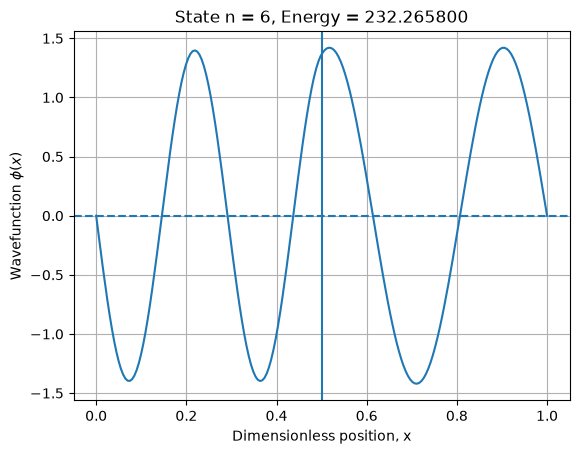

State = 7
Energy = 292.4321059888562


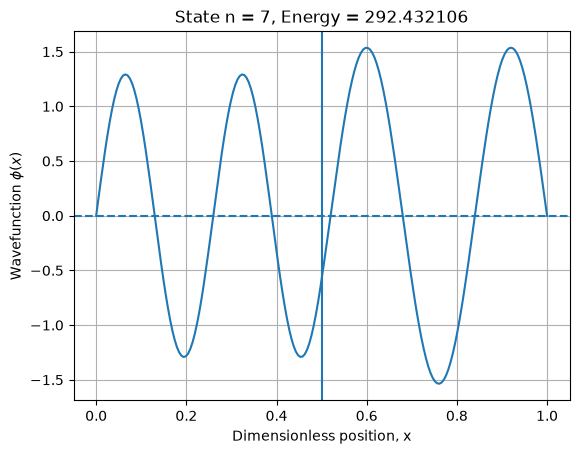

State = 8
Energy = 369.19505812224645


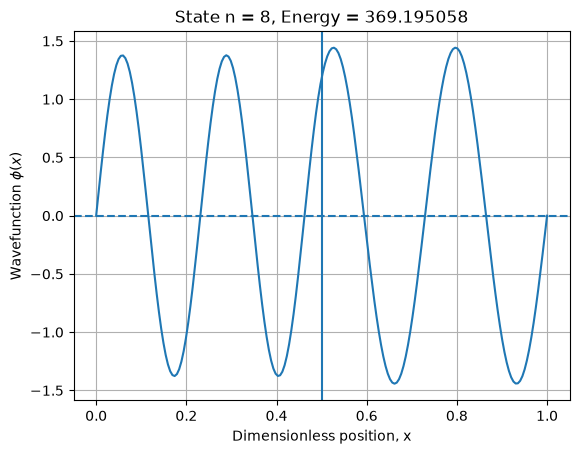

State = 9
Energy = 448.8825649329183


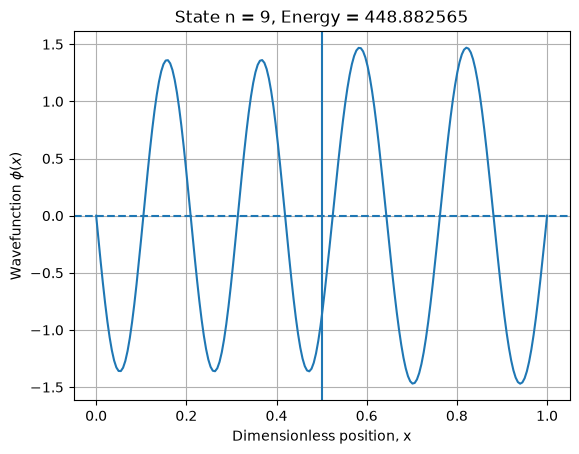

State = 10
Energy = 545.3280742934478


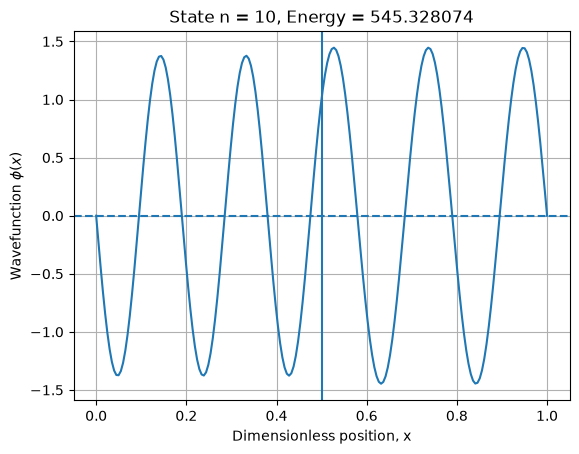

State = 11
Energy = 645.2382793260498


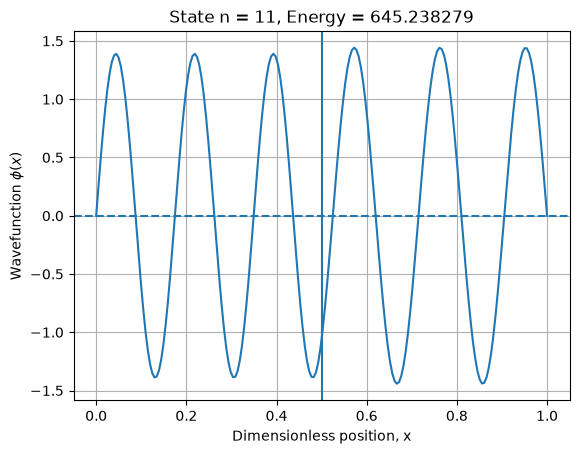

In [16]:
state_i = 0
state_f = 10

interior_points = 200
V0 = 100
x0 = 0.5

for state_index in range(state_i, state_f + 1):

    phi, full_grid, phi_normalized, energy_value = solve_step_potential(
        0, 1, interior_points, state_index, x0, V0
    )

    print("State =", state_index + 1)
    print("Energy =", energy_value)

    plot_step_potential(
        full_grid, phi_normalized, energy_value, state_index, x0
    )

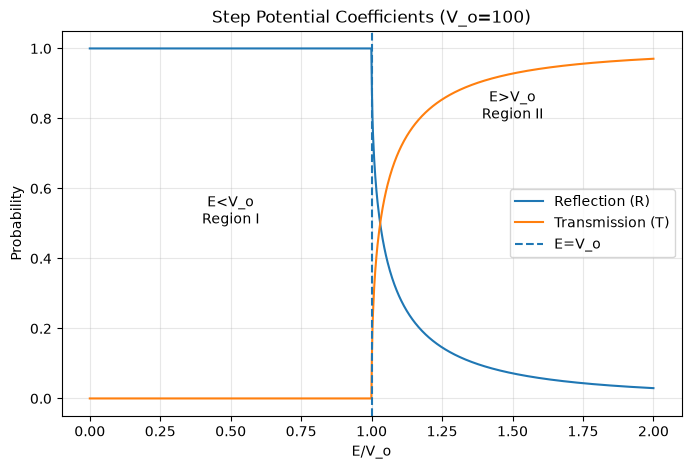

In [17]:
Eo_i=0
Eo_f=200
points=1000
E=np.linspace(Eo_i,Eo_f,points)
Vo=100

temp=np.sqrt((E-Vo).astype(complex))
reflection_coefficient_num = np.sqrt(E) - temp
reflection_coefficient_den = np.sqrt(E) + temp
reflection_coefficient=np.abs((np.sqrt(E)-temp)/(np.sqrt(E)+temp))**2
transmission_coefficient=1-reflection_coefficient

reflection_coefficient[0]=1
transmission_coefficient[0]=0

x_val=E/Vo

plt.figure(figsize=(8,5))
plt.plot(x_val,reflection_coefficient,label="Reflection (R)")
plt.plot(x_val,transmission_coefficient,label="Transmission (T)")
plt.axvline(1,linestyle="--",label="E=V_o")

plt.xlabel("E/V_o")
plt.ylabel("Probability")
plt.title("Step Potential Coefficients (V_o=100)")
plt.text(0.5,0.5,"E<V_o\nRegion I",ha="center")
plt.text(1.5,0.8,"E>V_o\nRegion II",ha="center")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

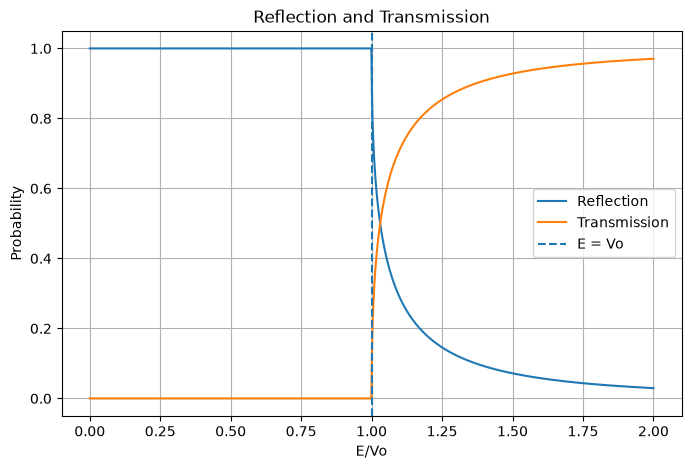

In [18]:
E = np.linspace(0, 200, 1000)
Vo = 100

root = np.sqrt((E-Vo).astype(complex))

R = np.abs((np.sqrt(E)-root)/(np.sqrt(E)+root))**2
T = 1-R

R[0] = 1
T[0] = 0

energy_ratio = E/Vo

plt.figure(figsize=(8,5))
plt.plot(energy_ratio, R, label="Reflection")
plt.plot(energy_ratio, T, label="Transmission")

plt.axvline(1, linestyle="--", label="E = Vo")

plt.xlabel("E/Vo")
plt.ylabel("Probability")
plt.title("Reflection and Transmission")
plt.grid()
plt.legend()
plt.show()